<a href="https://colab.research.google.com/github/davide-ario/BNN/blob/main/Bayesian_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bayesian Neural Networks for regression

This notebook introduces the building blocks used in the rest of the
repository, on simulated data where the true model is known:

1. a misspecified **linear regression** (OLS and Bayesian);
2. a **Bayesian neural network** (BNN) that learns the non-linear
   regression function from the data;
3. a **partially linear BNN**, $Y = \alpha + \beta X_0 + f(X_1, \dots, X_4) + \varepsilon$,
   which keeps an interpretable coefficient for the regressor of interest
   and lets a network absorb everything else.

The nested BNN, which chooses the functional form variable by variable, is
covered in [Nested-BayesianNN.ipynb](Nested-BayesianNN.ipynb).

## Setup

In [1]:
# On Google Colab, fetch the helper module and install PyMC.
import sys

if "google.colab" in sys.modules:
    !pip install -q "pymc>=6.4" "arviz>=1.0"
    !wget -q https://raw.githubusercontent.com/davide-ario/BNN/main/bnn_models.py

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import bnn_models as bm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

SEED = 0
rng = np.random.default_rng(SEED)
print(f"PyMC v{pm.__version__}")

PyMC v6.4.0


## 1. Simulated data

Five regressors are drawn from $U(0, 3)$, except $X_0$, which is driven by
a confounding factor $C \sim U(0, 3)$. An unobserved variable $L$ shares the
same factor, so it is correlated with $X_0$:

$$X_0 = C + U(0, 2), \qquad L = C + U(0, 3)$$

$$Y = 2 + 3X_0 - 2X_1^2 + 8X_1 + 7X_2 - 4X_3^3 + 3\sin(X_4) + L + \varepsilon,
\qquad \varepsilon \sim N(0, 2^2)$$

Because $L$ is omitted from every model, the best any of them can learn for
$X_0$ is the *predictive* slope
$3 + \operatorname{Cov}(X_0, L)/\operatorname{Var}(X_0) = 3 + 0.75/1.083 \approx 3.69$,
not the causal slope of 3.

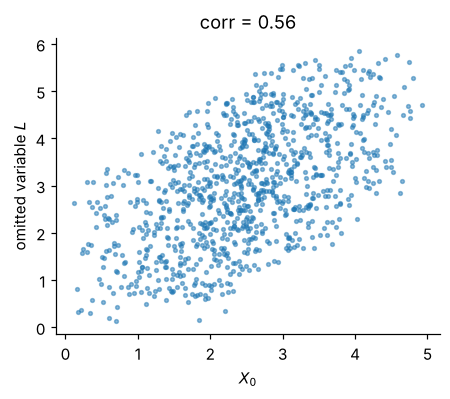

In [3]:
N = 1000
X = rng.uniform(0, 3, size=(N, 5))
confounder = rng.uniform(0, 3, size=N)
X[:, 0] = confounder + rng.uniform(0, 2, size=N)
latent = confounder + rng.uniform(0, 3, size=N)

Y = (2 + 3 * X[:, 0] - 2 * X[:, 1] ** 2 + 8 * X[:, 1] + 7 * X[:, 2]
     - 4 * X[:, 3] ** 3 + 3 * np.sin(X[:, 4]) + latent
     + rng.normal(0, 2, size=N))

BETA0_CAUSAL = 3.0
BETA0_PREDICTIVE = 3 + 0.75 / (0.75 + 4 / 12)

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.scatter(X[:, 0], latent, s=6, alpha=0.5)
ax.set(xlabel="$X_0$", ylabel="omitted variable $L$",
       title=f"corr = {np.corrcoef(X[:, 0], latent)[0, 1]:.2f}")
plt.show()

Train/test split (50/50) and standardisation with training-set moments.
Results are reported in the original units of $Y$.

In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.5, random_state=SEED)

x_scaler = StandardScaler().fit(X_train)
y_mean, y_sd = Y_train.mean(), Y_train.std()
Xs_train, Xs_test = x_scaler.transform(X_train), x_scaler.transform(X_test)
ys_train = (Y_train - y_mean) / y_sd


def to_y(ys):
    """Back-transform standardised outcomes to the original scale."""
    return ys * y_sd + y_mean

## 2. Linear regression (misspecified)

In [5]:
ols = sm.OLS(Y_train, sm.add_constant(X_train)).fit()
pred = {"OLS": ols.predict(sm.add_constant(X_test))}

idata_lin, _ = bm.fit_advi(bm.build_linear, Xs_train, ys_train,
                           n_iter=30_000, seed=SEED)
pred["Bayesian linear (ADVI)"] = to_y(
    bm.predict_mu(bm.build_linear, idata_lin, Xs_test).mean(axis=0))

beta_draws = (idata_lin.posterior["beta"].values.reshape(-1, 5)
              * y_sd / x_scaler.scale_)
pd.DataFrame({"OLS": ols.params[1:], "OLS s.e.": ols.bse[1:],
              "ADVI mean": beta_draws.mean(0), "ADVI sd": beta_draws.std(0)},
             index=[f"X{j}" for j in range(5)]).round(2)

,OLS,OLS s.e.,ADVI mean,ADVI sd
X0,4.29,0.53,4.84,0.48
X1,1.33,0.60,2.34,0.57
X2,7.38,0.62,7.50,0.61
X3,-31.67,0.62,-31.17,0.50
X4,0.46,0.61,0.52,0.60


The linear model gets the sign of most effects right, but forcing
$-4X_3^3$ and $-2X_1^2 + 8X_1$ into straight lines distorts the
coefficients and leaves a large share of the variance unexplained.

## 3. Bayesian neural network

Three fully connected ReLU hidden layers of 30 units, linear output.
Weights have $N(0, 1/n_{\text{in}})$ priors, biases $N(0, 1)$, and the noise
scale $\sigma$ is learned. The model is fitted by mini-batch ADVI (batches of
100, Adam optimiser).

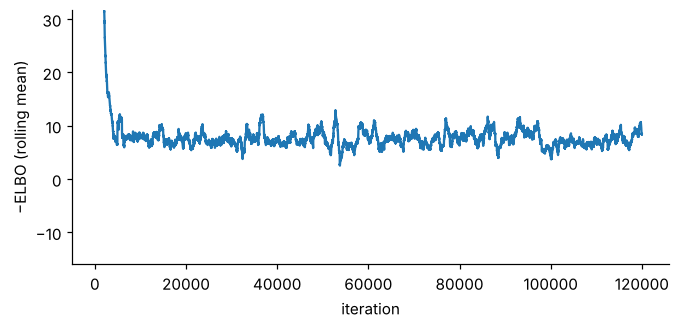

In [6]:
idata_bnn, hist_bnn = bm.fit_advi(bm.build_bnn, Xs_train, ys_train,
                                  n_iter=120_000, seed=SEED)
pred["BNN"] = to_y(bm.predict_mu(bm.build_bnn, idata_bnn, Xs_test).mean(axis=0))

fig, ax = plt.subplots(figsize=(7, 3))
loss = pd.Series(hist_bnn).rolling(1000).mean()
ax.plot(loss)
ax.set(xlabel="iteration", ylabel="−ELBO (rolling mean)",
       ylim=np.nanpercentile(loss[5000:], [0.5, 99.5]) + np.array([-20, 20]))
plt.show()

## 4. Partially linear BNN

$$Y = \alpha + \beta X_0 + f(X_1, X_2, X_3, X_4) + \varepsilon$$

The network $f$ does **not** receive $X_0$. If it did, it could absorb part
of the effect of $X_0$, and $\beta$ would not be identified. In return, the
posterior of $\beta$ is directly interpretable, like a regression
coefficient, while the network handles the non-linear controls.

In [7]:
idata_pl, _ = bm.fit_advi(bm.build_partially_linear_bnn, Xs_train, ys_train,
                          n_iter=120_000, seed=SEED)
pred["Partially linear BNN"] = to_y(
    bm.predict_mu(bm.build_partially_linear_bnn, idata_pl, Xs_test).mean(axis=0))

beta0_pl = idata_pl.posterior["beta"].values.reshape(-1) * y_sd / x_scaler.scale_[0]
beta0_table = pd.DataFrame({
    "estimate": [ols.params[1], beta0_pl.mean()],
    "s.e. / posterior sd": [ols.bse[1], beta0_pl.std()],
    "5%": [ols.conf_int(0.10)[1, 0], np.percentile(beta0_pl, 5)],
    "95%": [ols.conf_int(0.10)[1, 1], np.percentile(beta0_pl, 95)],
}, index=["OLS", "Partially linear BNN"]).round(2)
beta0_table

,estimate,s.e. / posterior sd,5%,95%
OLS,4.29,0.53,3.41,5.17
Partially linear BNN,3.75,0.14,3.51,3.98


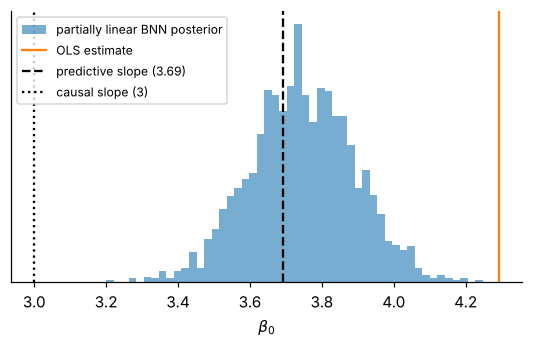

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(beta0_pl, bins=50, density=True, alpha=0.6,
        label="partially linear BNN posterior")
ax.axvline(ols.params[1], color="C1", label="OLS estimate")
ax.axvline(BETA0_PREDICTIVE, color="k", ls="--", label="predictive slope (3.69)")
ax.axvline(BETA0_CAUSAL, color="k", ls=":", label="causal slope (3)")
ax.set(xlabel=r"$\beta_0$", yticks=[])
ax.legend(fontsize=8)
plt.show()

## 5. Out-of-sample accuracy

In [9]:
pd.DataFrame({
    "RMSE": {k: mean_squared_error(Y_test, v) ** 0.5 for k, v in pred.items()},
    "R²": {k: r2_score(Y_test, v) for k, v in pred.items()},
}).round(3)

,RMSE,R²
OLS,13.191,0.840
Bayesian linear (ADVI),13.284,0.838
BNN,3.146,0.991
Partially linear BNN,2.850,0.993


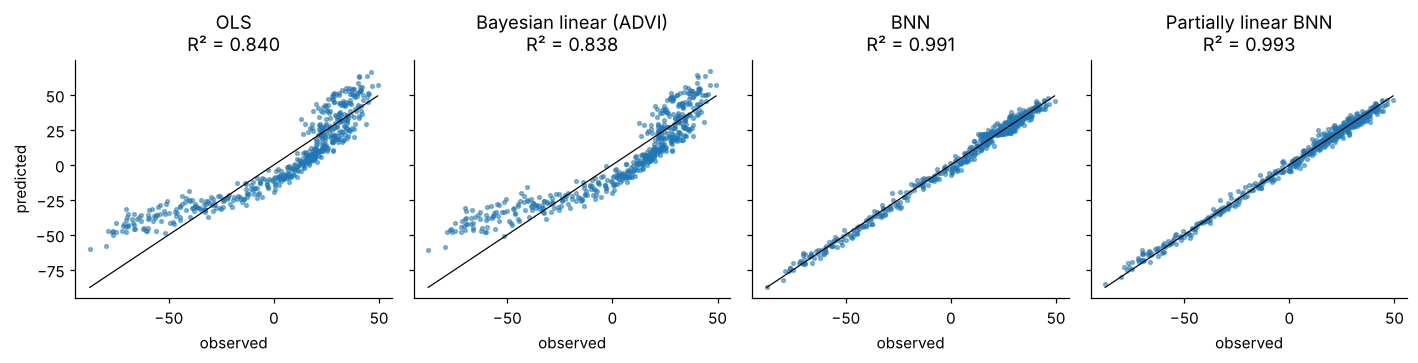

In [10]:
fig, axes = plt.subplots(1, len(pred), figsize=(13, 3.4), sharex=True, sharey=True)
lims = [Y_test.min(), Y_test.max()]
for ax, (name, p) in zip(axes, pred.items()):
    ax.scatter(Y_test, p, s=6, alpha=0.5)
    ax.plot(lims, lims, color="k", lw=0.8)
    ax.set(title=f"{name}\nR² = {r2_score(Y_test, p):.3f}", xlabel="observed")
axes[0].set_ylabel("predicted")
plt.tight_layout()
plt.show()

## 6. What the BNN has learned

Partial dependence of the BNN's predicted mean on each regressor, centred at
the lower end of its support, with 90% credible bands. The dashed line is the
true function from the simulation (for $X_0$, the predictive slope).

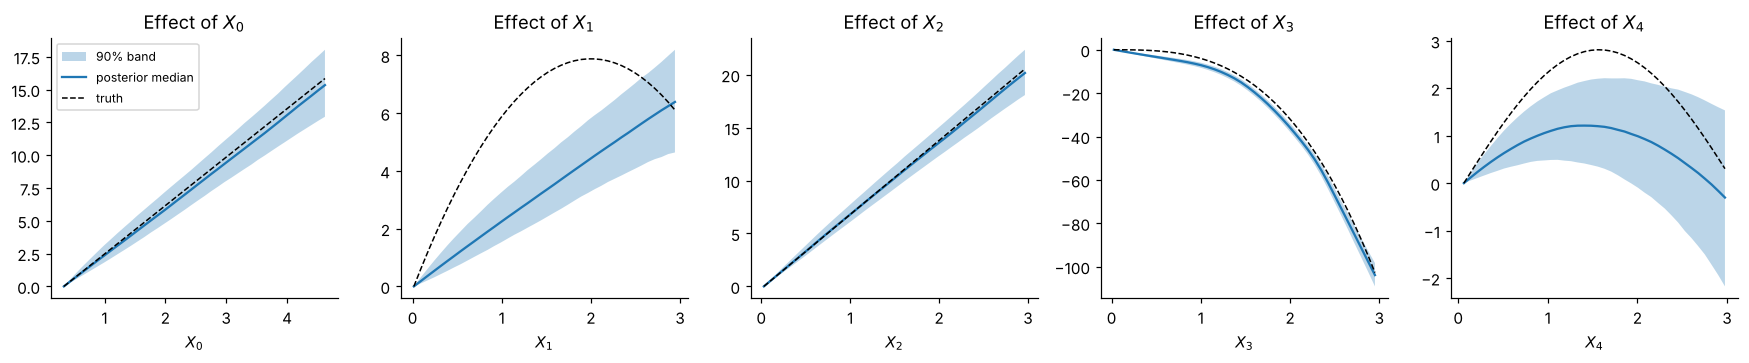

In [11]:
true_effect = {
    0: lambda x: BETA0_PREDICTIVE * x,
    1: lambda x: -2 * x ** 2 + 8 * x,
    2: lambda x: 7 * x,
    3: lambda x: -4 * x ** 3,
    4: lambda x: 3 * np.sin(x),
}
X_ref = X_test[:200]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for j, ax in enumerate(axes):
    lo_x, hi_x = np.percentile(X_train[:, j], [1, 99])
    grid = np.linspace(lo_x, hi_x, 40)
    # Centre at the lower end of the support (X_0 = 0 lies outside it).
    pd_draws = bm.partial_dependence(bm.build_bnn, idata_bnn, X_ref, j, grid,
                                     center=lo_x, transform=x_scaler.transform) * y_sd
    lo, mid, hi = np.percentile(pd_draws, [5, 50, 95], axis=0)
    ax.fill_between(grid, lo, hi, alpha=0.3, label="90% band")
    ax.plot(grid, mid, label="posterior median")
    ax.plot(grid, true_effect[j](grid) - true_effect[j](lo_x), "k--", lw=1,
            label="truth")
    ax.set(xlabel=f"$X_{j}$", title=f"Effect of $X_{j}$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Takeaways

* **Prediction.** The BNN explains 99% of the out-of-sample variance,
  against 84% for the linear model (RMSE about 3 against 13), without being
  told the functional form.
* **Interpretable coefficient.** The partially linear BNN estimates
  $\beta_0 \approx 3.75$ (90% interval 3.51–3.98), close to the
  predictive slope of 3.69. OLS gives 4.29, because its misspecified
  controls leak into the coefficient. Letting a network handle the controls
  removes that bias and also gives a much tighter interval.
* **What no model can fix.** Neither estimate recovers the causal slope of
  3: the omitted variable $L$ is correlated with $X_0$, and only better
  data or an identification strategy (e.g. an instrument) can remove that
  bias. Flexible functional forms address misspecification, not
  endogeneity.
* **Learned shapes.** The BNN recovers the linear and cubic effects
  closely. The concave effect of $X_1$ and the sine in $X_4$ are only
  partly captured: their contribution to $Y$ is small, and the prior
  shrinks them towards simpler shapes.